# Single dish vs interferometer: what is recovered of a diffuse Faraday screen

Make a sky, observe it, RM-synthesise, and compare true vs recovered RM and PI.

In [1]:
%matplotlib inline
%config InlineBackend.figure_format = 'png'
import matplotlib.pyplot as plt
from filter_possum import simulator as fs
plt.rcParams['figure.dpi'] = 70

## The sky

Polarised intensity 1 everywhere; RM = 30 ± 10 rad m⁻² (Kolmogorov) on a 5° × 5° field.

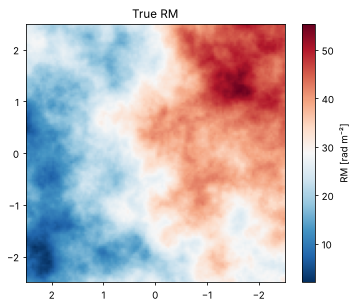

In [2]:
sky = fs.Sky(rm_mean=30, rm_sigma=10, rm_grad=0)
band = fs.BANDS['possum1']  # 800-1088 MHz, 288 x 1 MHz
plt.imshow(sky.rm(), origin='lower', extent=sky.extent, cmap='RdBu_r')
plt.colorbar(label='RM [rad m⁻²]'); plt.title('True RM');

## Observe with Parkes (64 m) and ASKAP, plus their joint combination

In [3]:
obs = fs.observe(sky, band, single_dish=fs.PARKES, interferometer=fs.ASKAP, combine='joint')
res = {k: fs.rmsynth(cube, band) for k, cube in obs.cubes.items()}

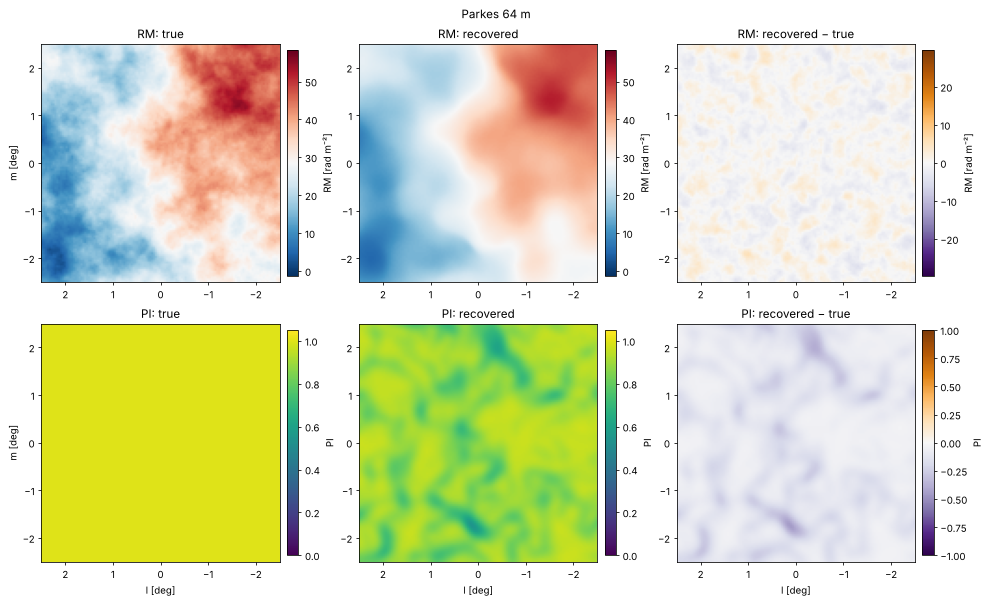

In [4]:
fs.plot_comparison(obs, res['sd'], 'Parkes 64 m');

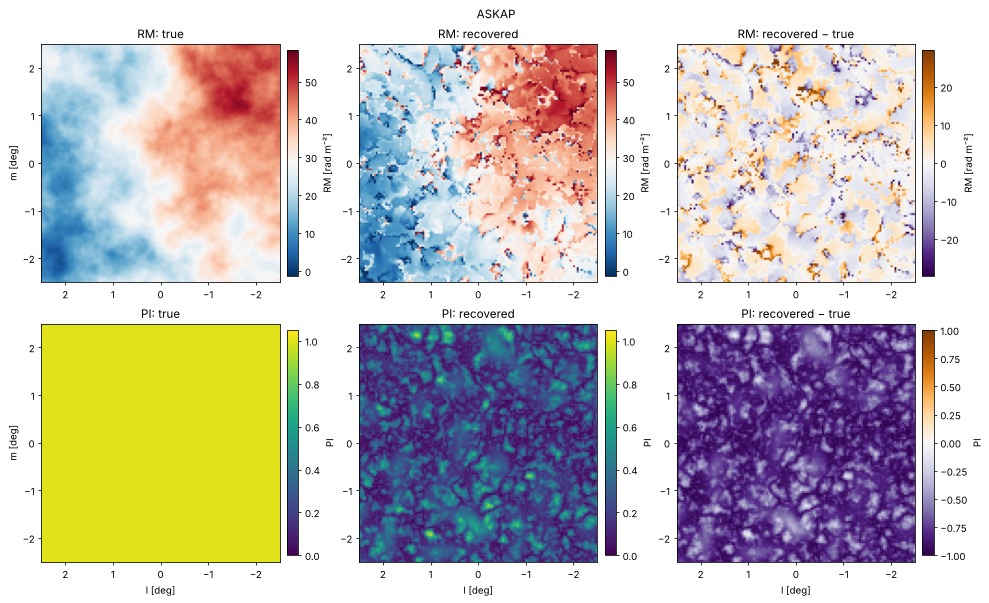

In [5]:
fs.plot_comparison(obs, res['int'], 'ASKAP');

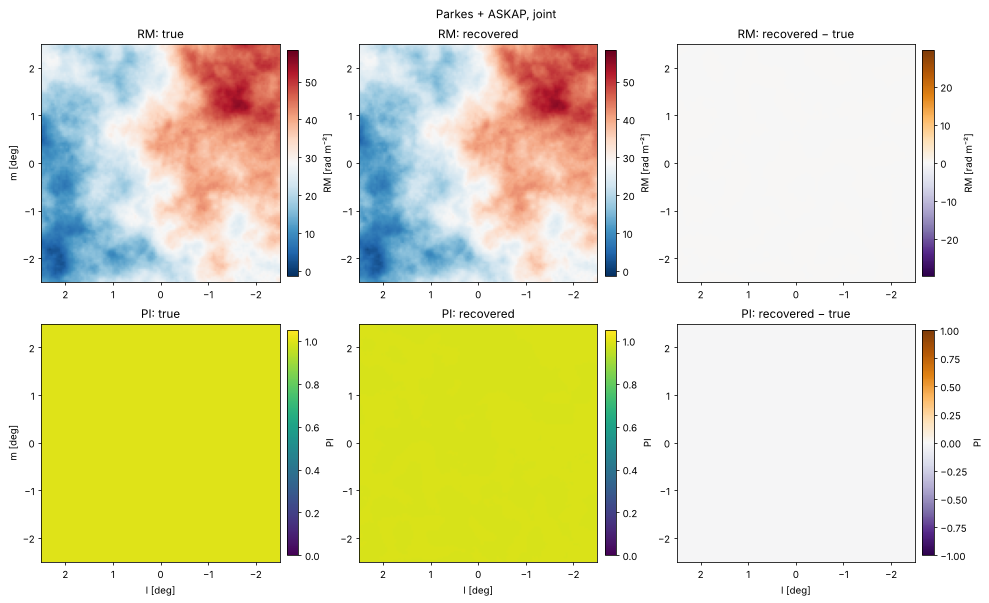

In [6]:
fs.plot_comparison(obs, res['comb'], 'Parkes + ASKAP, joint');

## Things to change

* sky: `fs.Sky(rm_sigma=2)`, `fs.Sky(rm_grad=50)`  (rad m⁻² per degree), `seed=...`
* band: `fs.BANDS['uhf']`, `fs.BANDS['lband']`, `fs.BANDS['possum12']`, or `fs.Band(((f_min, f_max, chan_width),))` in Hz
* interferometer: `fs.MEERKAT`, `fs.Interferometer(shortest_baseline_m=..., dish_diameter_m=...)`, or a fixed cut in wavelengths `fs.Interferometer(umin_lambda=80)`
* single dish: `fs.SingleDish(diameter_m=100)`, `model='sharp'`
* `combine='feather'` or `'joint'`; `uv_match=True` keeps the same angular scales in every channel

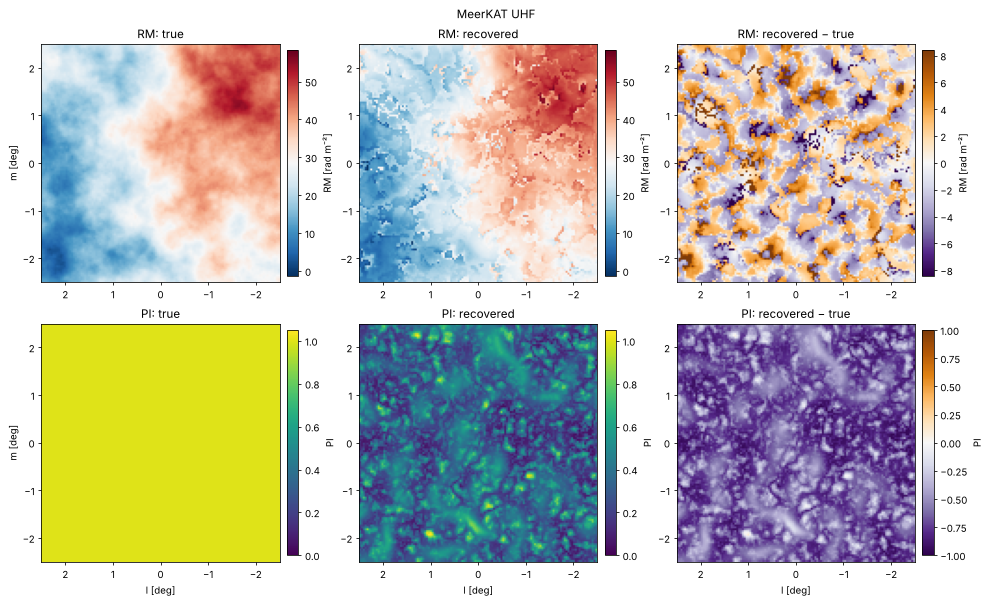

In [7]:
obs = fs.observe(fs.Sky(), fs.BANDS['uhf'], single_dish=None, interferometer=fs.MEERKAT)
fs.plot_comparison(obs, fs.rmsynth(obs.cubes['int'], obs.band), 'MeerKAT UHF');

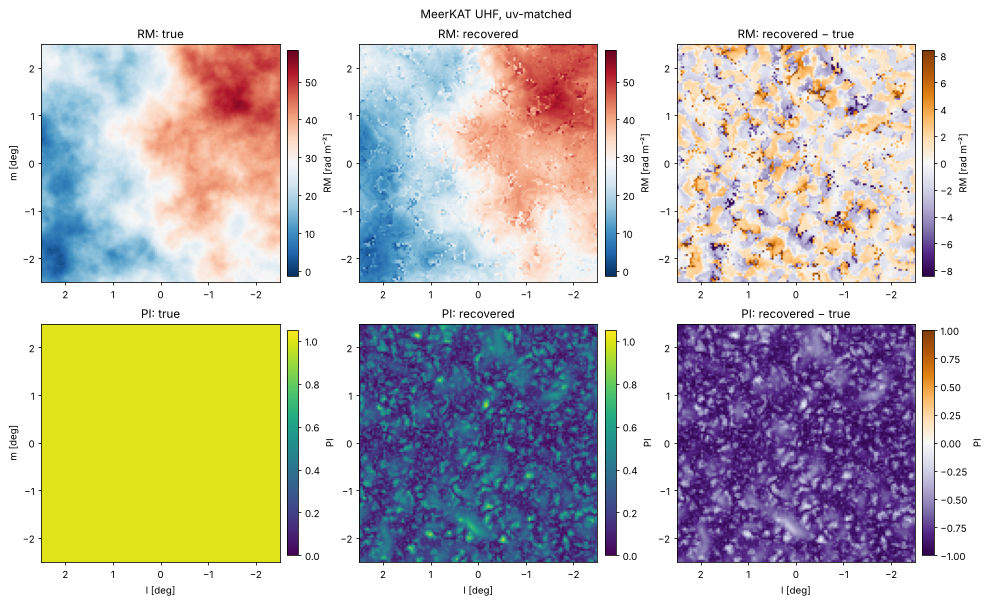

In [8]:
obs = fs.observe(fs.Sky(), fs.BANDS['uhf'], single_dish=None, interferometer=fs.MEERKAT, uv_match=True)
fs.plot_comparison(obs, fs.rmsynth(obs.cubes['int'], obs.band), 'MeerKAT UHF, uv-matched');